# Introduction to Data Science 2026

# Week 6: Recap

## Exercise 1 | Linear regression with feature selection

Download the [TED Talks](https://www.kaggle.com/rounakbanik/ted-talks) dataset from Kaggle. Your task is to predict both the ratings and the number of views of a given TED talk. You should focus only on the <span style="font-weight: bold">ted_main</span> table.

1. Download the data, extract the following ratings from column <span style="font-weight: bold">ratings</span>: <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, <span style="font-weight: bold">Inspiring</span>. Store these values into respective columns so that they are easier to access. Next, extract the tags from column <span style="font-weight: bold">tags</span>. Count the number of occurrences of each tag and select the top-100 most common tags. Create a binary variable for each of these and include them in your data table, so that you can directly see whether a given tag (among the top-100 tags) is used in a given TED talk or not. The dataset you compose should have dimension (2550, 104), and comprise of the 'views' column, the three columns with counts of "Funny", "Confusing and "Inspiring" ratings, and 100 columns which one-hot encode the top-100 most common tag columns.


In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import ast
import os
import glob

path = kagglehub.dataset_download("rounakbanik/ted-talks")
csv_files = glob.glob(os.path.join(path, "**", "ted_main.csv"), recursive=True)
df = pd.read_csv(csv_files[0])
df

,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520
2,124,New York Times columnist David Pogue takes aim...,1286,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",Simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292
3,200,"In an emotionally charged talk, MacArthur-winn...",1116,TED2006,1140912000,35,Majora Carter,Majora Carter: Greening the ghetto,1,1151367060,"[{'id': 3, 'name': 'Courageous', 'count': 760}...","[{'id': 1041, 'hero': 'https://pe.tedcdn.com/i...",Activist for environmental justice,"['MacArthur grant', 'activism', 'business', 'c...",Greening the ghetto,https://www.ted.com/talks/majora_carter_s_tale...,1697550
4,593,You've never seen data presented like this. Wi...,1190,TED2006,1140566400,48,Hans Rosling,Hans Rosling: The best stats you've ever seen,1,1151440680,"[{'id': 9, 'name': 'Ingenious', 'count': 3202}...","[{'id': 2056, 'hero': 'https://pe.tedcdn.com/i...",Global health expert; data visionary,"['Africa', 'Asia', 'Google', 'demo', 'economic...",The best stats you've ever seen,https://www.ted.com/talks/hans_rosling_shows_t...,12005869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2545,17,"Between 2008 and 2016, the United States depor...",476,TED2017,1496707200,4,Duarte Geraldino,Duarte Geraldino: What we're missing in the de...,1,1505851216,"[{'id': 3, 'name': 'Courageous', 'count': 24},...","[{'id': 2596, 'hero': 'https://pe.tedcdn.com/i...",Journalist,"['TED Residency', 'United States', 'community'...",What we're missing in the debate about immigra...,https://www.ted.com/talks/duarte_geraldino_wha...,450430
2546,6,How can you study Mars without a spaceship? He...,290,TED2017,1492992000,3,Armando Azua-Bustos,Armando Azua-Bustos: The most Martian place on...,1,1505919737,"[{'id': 22, 'name': 'Fascinating', 'count': 32...","[{'id': 2491, 'hero': 'https://pe.tedcdn.com/i...",Astrobiologist,"['Mars', 'South America', 'TED Fellows', 'astr...",The most Martian place on Earth,https://www.ted.com/talks/armando_azua_bustos_...,417470
2547,10,Science fiction visions of the future show us ...,651,TED2017,1492992000,1,Radhika Nagpal,Radhika Nagpal: What intelligent machines can ...,1,1506006095,"[{'id': 1, 'name': 'Beautiful', 'count': 14}, ...","[{'id': 2346, 'hero': 'https://pe.tedcdn.com/i...",Robotics engineer,"['AI', 'ants', 'fish', 'future', 'innovation',...",What intelligent machines can learn from a sch...,https://www.ted.com/talks/radhika_nagpal_what_...,375647
2548,32,In an unmissable talk about race and politics ...,1100,TEDxMileHigh,1499472000,1,Theo E.J. Wilson,Theo E.J. Wilson: A black man goes undercover ...,1,1506024042,"[{'id': 11, 'name': 'Longwinded', 'count': 3},...","[{'id': 2512, 'hero': 'https://pe.tedcdn.com/i...",Public intellectual,"['Internet', 'TEDx', 'United States', 'communi...",A black man goes undercover in the alt-right,https://www.t

In [ ]:
def get_rating(ratings, name):
    items = ast.literal_eval(ratings) if isinstance(ratings, str) else ratings
    return next((item["count"] for item in items
                 if item["name"].lower() == name.lower()), 0)

for rating in ["Funny", "Confusing", "Inspiring"]:
    df[rating] = df["ratings"].apply(lambda x: get_rating(x, rating))

df.head(4)

,comments,description,duration,event,film_date,languages,main_speaker,name,num_speaker,published_date,ratings,related_talks,speaker_occupation,tags,title,url,views,Funny,Confusing,Inspiring
0,4553,Sir Ken Robinson makes an entertaining and pro...,1164,TED2006,1140825600,60,Ken Robinson,Ken Robinson: Do schools kill creativity?,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 19645}, {...","[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...",Author/educator,"['children', 'creativity', 'culture', 'dance',...",Do schools kill creativity?,https://www.ted.com/talks/ken_robinson_says_sc...,47227110,19645,242,24924
1,265,With the same humor and humanity he exuded in ...,977,TED2006,1140825600,43,Al Gore,Al Gore: Averting the climate crisis,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...",Climate advocate,"['alternative energy', 'cars', 'climate change...",Averting the climate crisis,https://www.ted.com/talks/al_gore_on_averting_...,3200520,544,62,413
2,124,New York Times columnist David Pogue takes aim...,1286,TED2006,1140739200,26,David Pogue,David Pogue: Simplicity sells,1,1151367060,"[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...",Technology columnist,"['computers', 'entertainment', 'interface desi...",Simplicity sells,https://www.ted.com/talks/david_pogue_says_sim...,1636292,964,27,230
3,200,"In an emotionally charged talk, MacArthur-winn...",1116,TED2006,1140912000,35,Majora Carter,Majora Carter: Greening the ghetto,1,1151367060,"[{'id': 3, 'name': 'Courageous', 'count': 760}...","[{'id': 1041, 'hero': 'https://pe.tedcdn.com/i...",Activist for environmental justice,"['MacArthur grant', 'activism', 'business', 'c...",Greening the ghetto,https://www.ted.com/talks/majora_carter_s_tale...,1697550,59,32,1070


In [ ]:
df["tags_list"] = df["tags"].apply(ast.literal_eval)
top_100 = pd.Series([tag for tags in df["tags_list"] for tag in tags]).value_counts().head(100).index
top_100

Index(['technology', 'science', 'global issues', 'culture', 'TEDx', 'design',
       'business', 'entertainment', 'health', 'innovation', 'society', 'art',
       'social change', 'future', 'communication', 'creativity', 'biology',
       'humanity', 'collaboration', 'environment', 'economics', 'medicine',
       'brain', 'activism', 'education', 'community', 'history', 'TED Fellows',
       'children', 'music', 'invention', 'health care', 'politics', 'cities',
       'psychology', 'storytelling', 'women', 'performance', 'nature', 'war',
       'identity', 'engineering', 'computers', 'life', 'animals', 'humor',
       'Africa', 'exploration', 'personal growth', 'inequality', 'data',
       'government', 'medical research', 'photography', 'neuroscience',
       'climate change', 'Internet', 'visualizations', 'architecture',
       'live music', 'sustainability', 'disease', 'oceans', 'physics', 'green',
       'potential', 'happiness', 'biotech', 'mind', 'work', 'violence',
       'media

In [ ]:
for tag in top_100:
    df[tag] = df["tags_list"].apply(lambda tags: int(tag in tags))

tag_columns = list(top_100)
data = df[["views", "Funny", "Confusing", "Inspiring"] + tag_columns].copy()

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (2550, 104)


/var/folders/kx/qxglm7wd5zb28wv7z9lncnhc0000gn/T/ipykernel_5662/3880024723.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[tag] = df["tags_list"].apply(lambda tags: int(tag in tags))
/var/folders/kx/qxglm7wd5zb28wv7z9lncnhc0000gn/T/ipykernel_5662/3880024723.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[tag] = df["tags_list"].apply(lambda tags: int(tag in tags))
/var/folders/kx/qxglm7wd5zb28wv7z9lncnhc0000gn/T/ipykernel_5662/3880024723.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the 

,views,Funny,Confusing,Inspiring,technology,science,global issues,culture,TEDx,design,...,food,religion,family,peace,ecology,illness,demo,poetry,universe,social media
0,47227110,19645,242,24924,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,3200520,544,62,413,1,1,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1636292,964,27,230,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1697550,59,32,1070,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12005869,1390,72,2893,0,0,1,0,0,0,...,0,0,0,0,0,0,1,0,0,0


2. Construct a linear regression model to predict the number of views based on the data in the <span style="font-weight: bold">ted_main</span> table, including the binary variables for the top-100 tags that you just created.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

X = data[tag_columns]
y = data["views"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

views_model = LinearRegression()
views_model.fit(X_train, y_train)

predictions = views_model.predict(X_test)

print("R² score:", round(r2_score(y_test, predictions), 3))
print("Mean absolute error:", round(mean_absolute_error(y_test, predictions), 0))

R² score: 0.165
Mean absolute error: 1049049.0


3. Do the same for the <span style="font-weight: bold">Funny</span>, <span style="font-weight: bold">Confusing</span>, and <span style="font-weight: bold">Inspiring</span> ratings.

In [ ]:
rating_models = {}
for rating in ["Funny", "Confusing", "Inspiring"]:
    y = data[rating]
    X_train, X_test, y_train, y_test = train_test_split(data[tag_columns], y, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rating_models[rating] = model

    print(f"\n{rating} rating")
    print("R² score:", round(r2_score(y_test, predictions), 3))
    print("Mean absolute error:",round(mean_absolute_error(y_test, predictions), 2))


Funny rating
R² score: 0.21
Mean absolute error: 189.83

Confusing rating
R² score: 0.189
Mean absolute error: 15.78

Inspiring rating
R² score: 0.078
Mean absolute error: 487.91


4. You will probably notice that most of the tags are not useful in predicting the views and the ratings. You should use some kind of variable selection to prune the set of tags that are included in the model. You can use for example classical p-values or more modern [LASSO](https://en.wikipedia.org/wiki/Lasso_(statistics)) techniques. Which tags are the best predictors of each of the response variables?

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
targets = ["views", "Funny", "Confusing", "Inspiring"]
lasso_results = {}

for target in targets:
    X_train, X_test, y_train, y_test = train_test_split(
        data[tag_columns], data[target],test_size=0.2, random_state=42)

    model = make_pipeline(
        StandardScaler(),LassoCV(cv=5, max_iter=10000))
    model.fit(X_train, y_train)

    lasso = model.named_steps["lassocv"]
    coefficients = pd.Series(lasso.coef_, index=tag_columns)

    selected = coefficients[coefficients != 0].sort_values(key=abs, ascending=False)
    lasso_results[target] = selected
    print(f"\nBest predictors for {target}:")
    print(selected.head(10))


Best predictors for views:
psychology       284128.183759
work             198477.920631
culture          177163.637231
motivation       145837.649849
demo             130088.103951
mental health    119304.769857
brain            115564.079033
art             -102256.901877
global issues    -98316.033975
humor             91019.935410
dtype: float64

Best predictors for Funny:
humor            160.887115
creativity        41.550634
work              40.448341
culture           39.283059
entertainment     35.521003
children          35.138251
mind              28.143206
psychology        24.182498
neuroscience     -23.256428
motivation        19.737863
dtype: float64

Best predictors for Confusing:
culture          3.048491
physics          2.624556
brain            2.505710
evolution        2.414642
philosophy       2.053869
psychology       1.922190
entertainment    1.898468
innovation      -1.734911
religion         1.668790
science          1.551230
dtype: float64

Best predictors 

5. Produce summaries of your results. Could you recommend good tags – or tags to avoid! – for speakers targeting plenty of views and/or certain ratings?

In [ ]:
for target, results in lasso_results.items():
    print(f"\n{target}:")
    print("Positive predictors:")
    print(results[results > 0].head(5))
    print("Negative predictors:")
    print(results[results < 0].head(5))


views:
Positive predictors:
psychology    284128.183759
work          198477.920631
culture       177163.637231
motivation    145837.649849
demo          130088.103951
dtype: float64
Negative predictors:
art             -102256.901877
global issues    -98316.033975
design           -70313.274890
politics         -61754.107592
economics        -56253.436224
dtype: float64

Funny:
Positive predictors:
humor            160.887115
creativity        41.550634
work              40.448341
culture           39.283059
entertainment     35.521003
dtype: float64
Negative predictors:
neuroscience    -23.256428
art             -17.297388
design          -17.258862
global issues   -15.457952
live music      -13.345696
dtype: float64

Confusing:
Positive predictors:
culture       3.048491
physics       2.624556
brain         2.505710
evolution     2.414642
philosophy    2.053869
dtype: float64
Negative predictors:
innovation   -1.734911
Africa       -1.457982
animals      -1.214127
music        -1.0

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 2 | Symbol classification (part 2)

Note that it is strongly recommended to use Python in this exercise. However, if you can find a suitable AutoML implementation for your favorite language (e.g [here](http://h2o-release.s3.amazonaws.com/h2o/master/3888/docs-website/h2o-docs/automl.html) seems to be one for R) then you are free to use that language as well.

Use the preprocessed data from week 3 (you can also produce them using the example solutions of week 3).

1. This time train a *random forest classifier* on the data. A random forest is a collection of *decision trees*, which makes it an *ensemble* of classifiers. Each tree uses a random subset of the features to make its prediction. Without tuning any parameters, how is the accuracy?

In [8]:
from google.colab import files
uploaded = files.upload()

Saving HASYv2.tar.bz2 to HASYv2.tar.bz2


In [9]:
import os
import tarfile
archive_path = '/content/HASYv2.tar.bz2'
extract_dir = '/content/HASYv2'
os.makedirs(extract_dir, exist_ok=True)

with tarfile.open(archive_path, 'r:bz2') as tar:
    tar.extractall(extract_dir)

print("Dataset extracted successfully!")

/tmp/ipykernel_1720/1452772489.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extract_dir)


Dataset extracted successfully!


In [10]:
import pandas as pd
csv_path = None

for root, dirs, filenames in os.walk('/content/HASYv2'):
    if 'hasy-data-labels.csv' in filenames:
        csv_path = os.path.join(root, 'hasy-data-labels.csv')
        break

if csv_path is None:
    raise FileNotFoundError("Could not find hasy-data-labels.csv")

base_dir = os.path.dirname(csv_path)
df = pd.read_csv(csv_path)

print("Labels file:", csv_path)
print("Dataset directory:", base_dir)
print("Total images listed:", len(df))

Labels file: /content/HASYv2/hasy-data-labels.csv
Dataset directory: /content/HASYv2
Total images listed: 168233


In [11]:
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
filtered_df = df[df['symbol_id'].between(70, 79)].copy()
X_list = []
y_list = []
for _, row in filtered_df.iterrows():
    img_path = os.path.join(base_dir, row['path'])

    img = Image.open(img_path).convert('L')
    X_list.append(np.array(img, dtype=np.float32).flatten())
    y_list.append(row['symbol_id'])

X = np.array(X_list)
y = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Classes:", np.unique(y))

X shape: (1020, 1024)
y shape: (1020,)
Classes: [70 71 72 73 74 75 76 77 78 79]


In [12]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    shuffle=True,
    stratify=y)

print("Training set:", X_train.shape, y_train.shape)
print("Test set:", X_test.shape, y_test.shape)

Training set: (816, 1024) (816,)
Test set: (204, 1024) (204,)


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest test accuracy: {rf_accuracy * 100:.2f}%")

Random Forest test accuracy: 83.33%


2. The amount of trees to use as a part of the random forest is an example of a hyperparameter, because it is a parameter that is set prior to the learning process. In contrast, a parameter is a value in the model that is learned from the data. Train 20 classifiers, with varying amounts of decision trees starting from 10 up until 200, and plot the test accuracy as a function of the amount of classifiers. Does the accuracy keep increasing? Is more better?

Trees:  10 | Accuracy: 75.98%
Trees:  20 | Accuracy: 79.41%
Trees:  30 | Accuracy: 79.90%
Trees:  40 | Accuracy: 82.84%
Trees:  50 | Accuracy: 81.86%
Trees:  60 | Accuracy: 80.39%
Trees:  70 | Accuracy: 79.90%
Trees:  80 | Accuracy: 81.86%
Trees:  90 | Accuracy: 82.84%
Trees: 100 | Accuracy: 83.33%
Trees: 110 | Accuracy: 82.35%
Trees: 120 | Accuracy: 82.35%
Trees: 130 | Accuracy: 82.84%
Trees: 140 | Accuracy: 83.33%
Trees: 150 | Accuracy: 82.35%
Trees: 160 | Accuracy: 82.84%
Trees: 170 | Accuracy: 82.84%
Trees: 180 | Accuracy: 82.84%
Trees: 190 | Accuracy: 82.84%
Trees: 200 | Accuracy: 82.84%


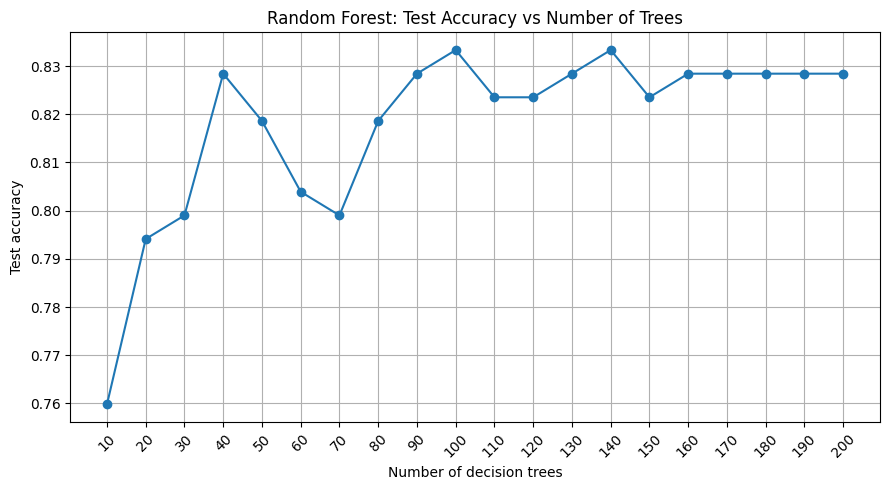

In [14]:
tree_counts = list(range(10, 201, 10))
test_accuracies = []

for n_trees in tree_counts:
    model = RandomForestClassifier(
        n_estimators=n_trees,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    test_accuracies.append(accuracy)

    print(f"Trees: {n_trees:3d} | Accuracy: {accuracy * 100:.2f}%")

plt.figure(figsize=(9, 5))
plt.plot(tree_counts, test_accuracies, marker='o')
plt.xlabel("Number of decision trees")
plt.ylabel("Test accuracy")
plt.title("Random Forest: Test Accuracy vs Number of Trees")
plt.xticks(tree_counts, rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

3. If we had picked the amount of decision trees by taking the value with the best test accuracy from the last plot, we would have *overfit* our hyperparameters to the test data. Can you see why it is a mistake to tune hyperparameters of your model by using the test data?

In [ ]:
#The test set should be reserved for the final evaluation, while hyperparameters should be selected using training and validation data.

*You can use this markdown cell to write down your thoughts.*

4. Reshuffle and resplit the data so that it is divided in 3 parts: training (80%), validation (10%) and test (10%). Repeatedly train a model of your choosing (e.g random forest) on the training data, and evaluate it’s performance on the validation set, while tuning the hyperparameters so that the accuracy on the validation set increases. Then, finally evaluate the performance of your model on the test data. What can you say in terms of the generalization of your model?

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

best_model = None
best_val_accuracy = -1
best_params = None
for n_trees in [50, 100, 150, 200]:
    for max_depth in [None, 20, 40]:
        model = RandomForestClassifier(
            n_estimators=n_trees,
            max_depth=max_depth,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train, y_train)
        val_predictions = model.predict(X_val)
        val_accuracy = accuracy_score(y_val, val_predictions)

        print(
            f"Trees={n_trees}, depth={max_depth}, "
            f"validation accuracy={val_accuracy * 100:.2f}%"
        )

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_model = model
            best_params = {
                "n_estimators": n_trees,
                "max_depth": max_depth
            }

print("\nBest hyperparameters:", best_params)
print(f"Best validation accuracy: {best_val_accuracy * 100:.2f}%")
test_predictions = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Final test accuracy: {test_accuracy * 100:.2f}%")

Training samples: 816
Validation samples: 102
Test samples: 102
Trees=50, depth=None, validation accuracy=83.33%
Trees=50, depth=20, validation accuracy=84.31%
Trees=50, depth=40, validation accuracy=83.33%
Trees=100, depth=None, validation accuracy=86.27%
Trees=100, depth=20, validation accuracy=86.27%
Trees=100, depth=40, validation accuracy=86.27%
Trees=150, depth=None, validation accuracy=85.29%
Trees=150, depth=20, validation accuracy=86.27%
Trees=150, depth=40, validation accuracy=85.29%
Trees=200, depth=None, validation accuracy=86.27%
Trees=200, depth=20, validation accuracy=87.25%
Trees=200, depth=40, validation accuracy=86.27%

Best hyperparameters: {'n_estimators': 200, 'max_depth': 20}
Best validation accuracy: 87.25%
Final test accuracy: 81.37%


**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**

## Exercise 3 | TPOT

The process of picking a suitable model, evaluating its performance and tuning the hyperparameters is very time consuming. A new idea in machine learning is the concept of automating this by using an optimization algorithm to find the best model in the space of models and their hyperparameters. Have a look at [TPOT](https://github.com/EpistasisLab/tpot), an automated ML solution that finds a good model and a good set of hyperparameters automatically. Try it on this data, it should outperform simple models like the ones we tried easily. Note that running the algorithm might take a while, depending on the strength of your computer.

*Note*: In case it is running for too long, try checking if the parameters you are using when calling TPOT are reasonable, i.e. try reducing number of ‘generations’ or ‘population_size’. TPOT uses cross-validation internally, so we don’t need our own validation set.

In [ ]:
%pip install -U "TPOT==1.1.0"

In [4]:
import tpot
print(tpot.__version__)

/usr/local/lib/python3.13/dist-packages/stopit/__init__.py:10: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


1.1.0


In [16]:
from tpot import TPOTClassifier
from sklearn.metrics import accuracy_score, classification_report
tpot_model = TPOTClassifier(
    search_space="linear-light",
    scorers=["accuracy"],
    scorers_weights=[1],
    cv=3,
    max_time_mins=10,
    n_jobs=2,
    random_state=42,
    verbose=2)

tpot_model.fit(X_train, y_train)
tpot_predictions = tpot_model.predict(X_test)

tpot_accuracy = accuracy_score(y_test, tpot_predictions)
print(f"TPOT test accuracy: {tpot_accuracy * 100:.2f}%")
print(classification_report(y_test, tpot_predictions))
print(tpot_model.fitted_pipeline_)

INFO:distributed.http.proxy:To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:46835
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:38971'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:38313'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:38637 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:38637
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:39724
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:44851 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:44851
INFO:distributed.core:Starting established connection to tcp://127

TPOT test accuracy: 0.00%
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       0.0
           1       0.00      0.00      0.00       0.0
           2       0.00      0.00      0.00       0.0
           3       0.00      0.00      0.00       0.0
           4       0.00      0.00      0.00       0.0
           5       0.00      0.00      0.00       0.0
           6       0.00      0.00      0.00       0.0
           7       0.00      0.00      0.00       0.0
           8       0.00      0.00      0.00       0.0
           9       0.00      0.00      0.00       0.0
          70       0.00      0.00      0.00      13.0
          71       0.00      0.00      0.00      12.0
          72       0.00      0.00      0.00      13.0
          73       0.00      0.00      0.00      12.0
          74       0.00      0.00      0.00       6.0
          75       0.00      0.00      0.00       8.0
          76       0.00      0.00      0.00      10.0
 

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

**Remember to submit your code on the MOOC platform. You can return this Jupyter notebook (.ipynb) or .py, .R, etc depending on your programming preferences.**